In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt



In [ ]:
df = pd.read_csv("/content/Students Performance Dataset.csv")
df
sns.set_theme(style="whitegrid")

df.head()
df.shape
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


,math score,reading score,writing score
count,1000.000000,1000.000000,1000.000000
mean,71.166000,72.771000,72.399000
std,15.531312,15.030585,15.236665
min,27.000000,25.000000,16.000000
25%,60.000000,62.750000,63.000000
50%,72.000000,73.000000,73.000000
75%,82.000000,84.000000,83.000000
max,100.000000,100.000000,100.000000


In [ ]:
df.columns = df.columns.str.strip().str.lower()   # consistent names
print("Missing:\n", df.isna().sum())
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()

Missing:
 gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64
Duplicates: 1


In [ ]:
scores = ["math score", "reading score", "writing score"]

df["average score"] = df[scores].mean(axis=1).round(1)

df["grade"] = pd.cut(
    df["average score"],
    bins=[-1, 59, 69, 79, 89, 100],
    labels=["F", "D", "C", "B", "A"]
)

df["pass"] = df["average score"] >= 60
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,average score,grade,pass
0,female,group D,associate's degree,standard,none,74,87,83,81.3,B,True
1,male,group E,master's degree,free/reduced,none,75,55,69,66.3,D,True
2,male,group E,high school,free/reduced,none,41,43,44,42.7,F,False
3,female,group C,some college,free/reduced,completed,60,64,60,61.3,D,True
4,female,group C,associate's degree,standard,completed,73,89,84,82.0,B,True


In [ ]:
print(df[scores + ["average score"]].describe().round(2))
print(f"Pass rate: {df['pass'].mean():.1%}")
print(df["grade"].value_counts().sort_index())

       math score  reading score  writing score  average score
count      999.00         999.00         999.00         999.00
mean        71.14          72.74          72.37          72.08
std         15.51          15.01          15.22          13.91
min         27.00          25.00          16.00          24.00
25%         60.00          62.50          63.00          62.30
50%         72.00          73.00          73.00          73.00
75%         82.00          84.00          83.00          81.70
max        100.00         100.00         100.00         100.00
Pass rate: 81.1%
grade
F    177
D    234
C    282
B    191
A    115
Name: count, dtype: int64


In [ ]:
cat_cols = ["gender", "race/ethnicity", "parental level of education",
            "lunch", "test preparation course"]

for col in cat_cols:
    print(f"\n--- Average score by {col} ---")
    print(df.groupby(col)["average score"]
            .agg(["count", "mean", "median"]).round(2)
            .sort_values("mean", ascending=False))


--- Average score by gender ---
        count   mean  median
gender                      
female    491  72.64    73.7
male      508  71.55    72.7

--- Average score by race/ethnicity ---
                count   mean  median
race/ethnicity                      
group B           193  73.30   74.30
group C           325  72.77   74.30
group E           153  72.75   73.70
group A            86  71.64   71.30
group D           242  69.93   69.85

--- Average score by parental level of education ---
                             count   mean  median
parental level of education                      
bachelor's degree              121  76.96    77.7
master's degree                 50  75.76    75.0
associate's degree             207  73.24    74.3
some college                   234  72.73    73.7
high school                    215  69.81    70.7
some high school               172  68.16    68.0

--- Average score by lunch ---
              count   mean  median
lunch                         

In [ ]:
gaps = {c: df.groupby(c)["average score"].mean().agg(lambda s: s.max() - s.min())
        for c in cat_cols}
pd.Series(gaps).sort_values(ascending=False).round(2)

,0
parental level of education,8.80
lunch,7.16
test preparation course,5.03
race/ethnicity,3.37
gender,1.09


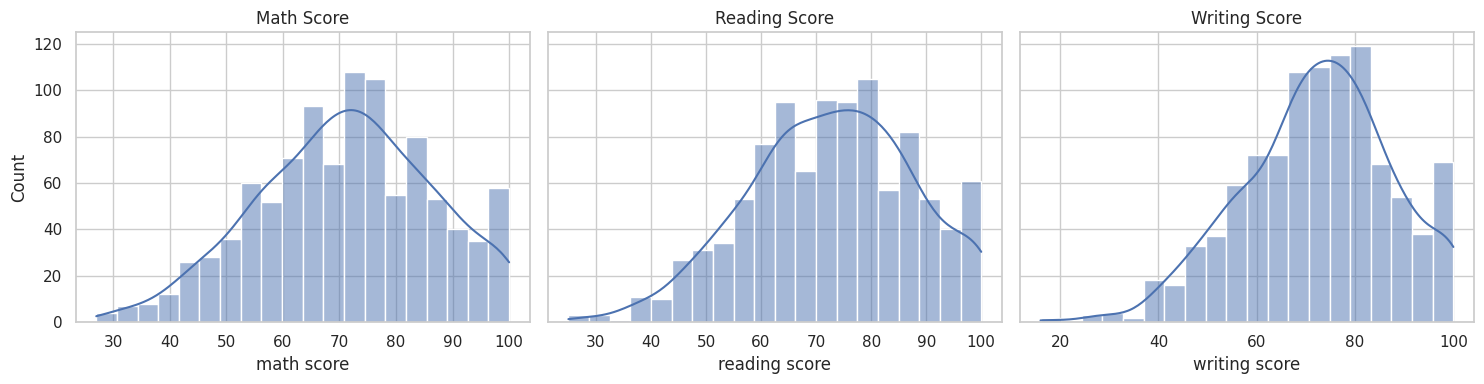

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, col in zip(axes, scores):
    sns.histplot(df[col], bins=20, kde=True, ax=ax)
    ax.set_title(col.title())
plt.tight_layout()
plt.show()

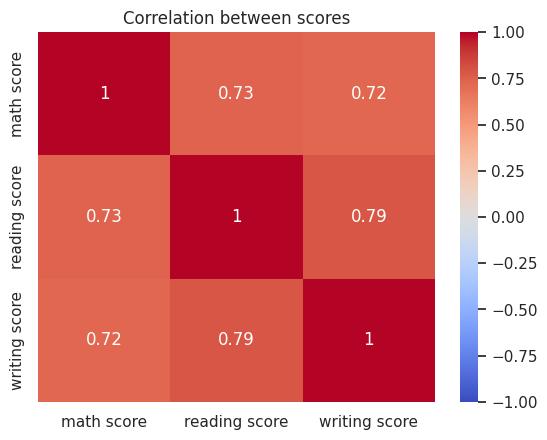

In [ ]:
sns.heatmap(df[scores].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between scores")
plt.show()

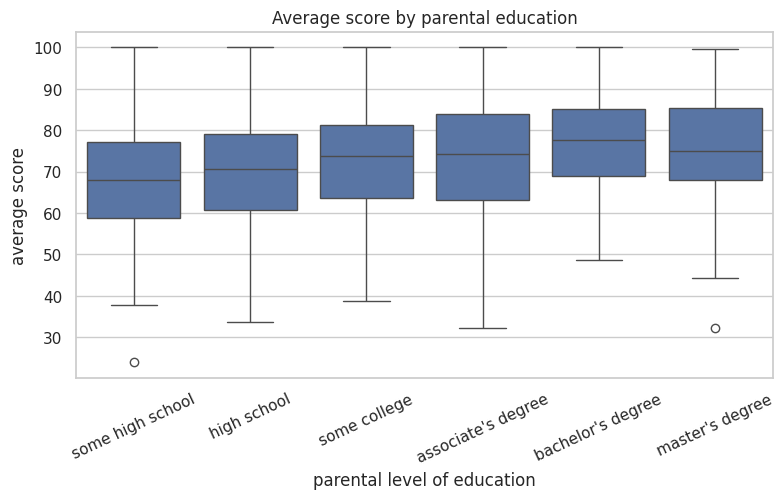

In [ ]:
order = ["some high school", "high school", "some college",
         "associate's degree", "bachelor's degree", "master's degree"]
plt.figure(figsize=(9, 4.5))
sns.boxplot(data=df, x="parental level of education", y="average score", order=order)
plt.xticks(rotation=25)
plt.title("Average score by parental education")
plt.show()

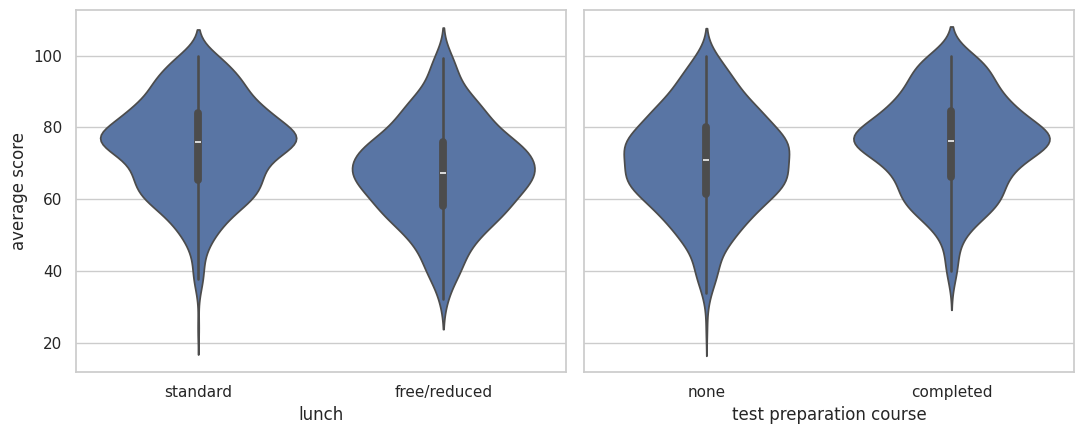

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
sns.violinplot(data=df, x="lunch", y="average score", ax=axes[0])
sns.violinplot(data=df, x="test preparation course", y="average score", ax=axes[1])
plt.tight_layout()
plt.show()

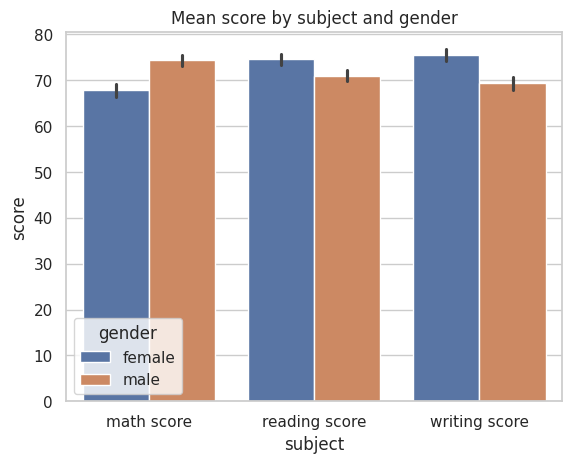

In [ ]:
long = df.melt(id_vars="gender", value_vars=scores, var_name="subject", value_name="score")
sns.barplot(data=long, x="subject", y="score", hue="gender")
plt.title("Mean score by subject and gender")
plt.show()

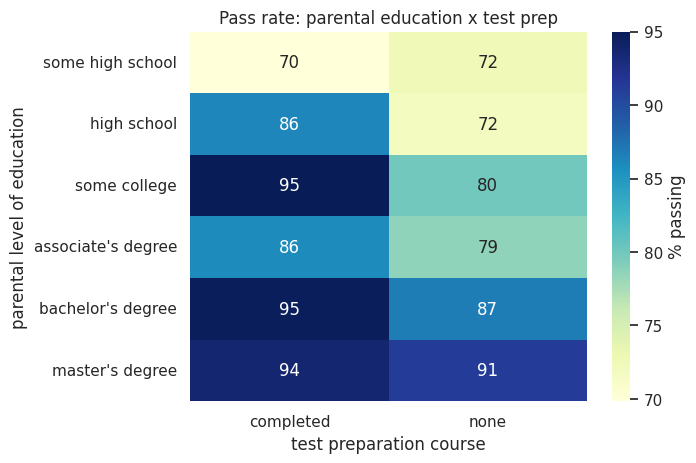

In [ ]:
pv = df.pivot_table(index="parental level of education",
                    columns="test preparation course",
                    values="pass", aggfunc="mean").reindex(order) * 100
sns.heatmap(pv, annot=True, fmt=".0f", cmap="YlGnBu", cbar_kws={"label": "% passing"})
plt.title("Pass rate: parental education x test prep")
plt.show()

In [ ]:
from scipy import stats
a = df[df["test preparation course"] == "completed"]["average score"]
b = df[df["test preparation course"] == "none"]["average score"]
print(stats.ttest_ind(a, b))

TtestResult(statistic=np.float64(5.520435638796513), pvalue=np.float64(4.3122067154686135e-08), df=np.float64(997.0))


In [ ]:
print(a.mean(), b.mean(), a.mean() - b.mean())

75.35890804597702 70.33364055299539 5.025267492981627


## Conclusion

### Objective
To analyze which factors influence student exam performance (math, reading and writing scores).

### Method
- Cleaned the data (checked for missing values, removed duplicates)
- Created an average score, a letter grade and a pass/fail flag (pass = average of 60 or above)
- Compared groups using `groupby` summaries
- Visualized distributions and group differences with Seaborn
- Tested the effect of test preparation with an independent t-test

### Key Findings
1. **Overall performance:** The average score was about 72, and roughly 81% of students passed.
2. **Parental education had the largest gap.** Students whose parents held a bachelor's degree averaged about 77, versus about 68 for those whose parents had some high school (a gap of about 9 points).
3. **Lunch type mattered.** Students with standard lunch averaged about 74.6, versus 67.4 for free/reduced lunch (a gap of about 7 points).
4. **Test preparation helped.** Students who completed the course averaged 75.4 versus 70.3 for those who did not, a difference of about 5 points. The t-test confirmed it was statistically significant (t = 5.52, p < 0.001).
5. **Gender and race/ethnicity showed small gaps** (about 1 point and 3 points).
6. **Subjects are strongly related.** Students who did well in one subject tended to do well in the others.

### Limitations
- Correlation does not imply causation. For example, lunch type may reflect family income rather than cause score differences.
- The dataset has no information on study hours, attendance or school quality.
- The analysis is descriptive. It does not predict individual outcomes.

### Next Steps
- Build a regression model to measure each factor's effect while controlling for the others
- Train a simple classifier to predict pass/fail
- Repeat the analysis on a larger real-world dataset

